# ALD-SC v2.0.x — encoding quality

Measure how much signal a fixed-size spectral code retains. Compare the graph eigenbasis, PCA fitted only on training signals, and a random orthonormal basis.

**Evidence scope:** synthetic signals on a 128-node analytical path graph. This measures linear spectral-chart encoding, not learned image encoding, perceptual quality or an ArrowSpace corpus benchmark. The shared basis is amortised; coefficient count is not compressed file size.

Run from the repository root or `notebooks/`, using the project `.venv` kernel. Setup: `uv sync --locked --group notebooks`. Full automated execution from the repository root: `uv run --locked --group notebooks python scripts/execute_notebooks.py`.

The locally specified protocol is `docs/experiments/prime-gating-protocol.md`. Seed: **3407**.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/ald_sc').is_dir())
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'scripts')]
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ald_sc import __version__, encoding_experiment
from ald_sc.prime_gating import path_basis
from run_prime_study import encoding_figure, verify_exported_result
assert Path(sys.prefix).absolute() == ROOT / '.venv'
assert __version__.split('.')[:2] == ['2', '0']
%matplotlib inline
print('ALD-SC', __version__, '| NumPy', np.__version__)


ALD-SC 2.0.2 | NumPy 2.5.1


## What is being encoded?

For orthonormal columns, encoding and reconstruction are

$$c = U_q^\top a,\qquad \hat a = U_q c.$$

The graph basis is known analytically. PCA sees 1,024 training signals and never the 2,048 evaluation signals. The population has known zero mean, so every encoder is linear through the origin. Smooth signals have modal standard deviation $$1/(1+4\nu_k)$$; broadband signals have standard deviation one. No primes are used in the signal generator.

The broadband regime checks whether an apparent advantage merely reflects the assumed smoothness. All ranks and comparators are fixed before evaluation.

{'seed': 3407, 'features': 128, 'n_train': 1024, 'n_test': 2048, 'ranks': [8, 16, 32, 64, 128], 'n_boot': 2000, 'version': '2.0.0'}


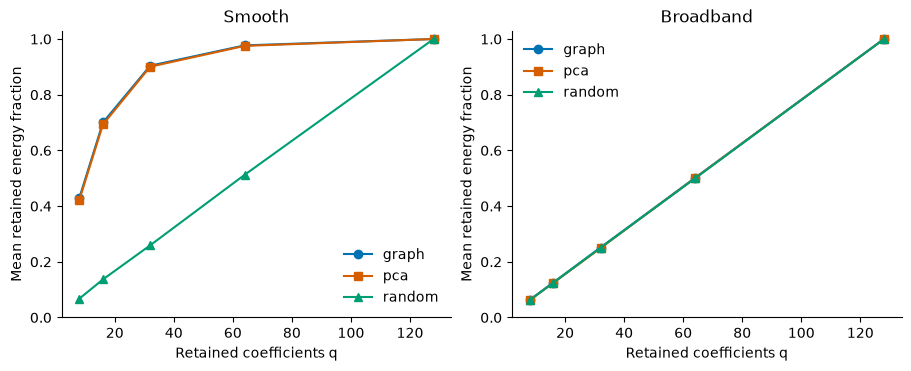

| Regime | Basis | q | MSE | Energy retained | Paired delta vs graph [95% interval] |
|---|---|---:|---:|---:|---:|
| smooth | graph | 8 | 0.0746392 | 0.4294 | +0 [+0, +0] |
| smooth | pca | 8 | 0.0756104 | 0.4222 | +0.000971242 [+0.000624479, +0.00130637] |
| smooth | random | 8 | 0.12501 | 0.0676 | +0.0503709 [+0.0491169, +0.0515643] |
| smooth | graph | 16 | 0.0382575 | 0.7003 | +0 [+0, +0] |
| smooth | pca | 16 | 0.039255 | 0.6931 | +0.00099748 [+0.000845436, +0.00115302] |
| smooth | random | 16 | 0.115743 | 0.1367 | +0.0774859 [+0.076242, +0.0788195] |
| smooth | graph | 32 | 0.0119843 | 0.9041 | +0 [+0, +0] |
| smooth | pca | 32 | 0.0124537 | 0.9006 | +0.000469391 [+0.000418683, +0.000517142] |
| smooth | random | 32 | 0.099251 | 0.2593 | +0.0872667 [+0.0859938, +0.0884784] |
| smooth | graph | 64 | 0.00284224 | 0.9772 | +0 [+0, +0] |
| smooth | pca | 64 | 0.00307419 | 0.9753 | +0.000231946 [+0.000217245, +0.00024668] |
| smooth | random | 64 | 0.0653326 | 0.5125 | +0.0624904 [+0.061624, +0.0633642] |
| smooth | graph | 128 | 1.19784e-29 | 1.0000 | +0 [+0, +0] |
| smooth | pca | 128 | 4.75522e-31 | 1.0000 | -1.15029e-29 [-1.16964e-29, -1.13123e-29] |
| smooth | random | 128 | 1.16471e-31 | 1.0000 | -1.18619e-29 [-1.2058e-29, -1.16696e-29] |
| broadband | graph | 8 | 0.94133 | 0.0630 | +0 [+0, +0] |
| broadband | pca | 8 | 0.942357 | 0.0620 | +0.00102697 [-0.000762714, +0.00283538] |
| broadband | random | 8 | 0.941739 | 0.0626 | +0.00040884 [-0.00144532, +0.00232079] |
| broadband | graph | 16 | 0.878434 | 0.1256 | +0 [+0, +0] |
| broadband | pca | 16 | 0.879692 | 0.1243 | +0.00125786 [-0.00114507, +0.00370025] |
| broadband | random | 16 | 0.879205 | 0.1248 | +0.000771051 [-0.00166569, +0.00338028] |
| broadband | graph | 32 | 0.752174 | 0.2513 | +0 [+0, +0] |
| broadband | pca | 32 | 0.754422 | 0.2490 | +0.00224804 [-0.0009238, +0.00555919] |
| broadband | random | 32 | 0.752779 | 0.2506 | +0.000604743 [-0.00267057, +0.00390214] |
| broadband | graph | 64 | 0.500758 | 0.5013 | +0 [+0, +0] |
| broadband | pca | 64 | 0.5017 | 0.5008 | +0.000941938 [-0.00285497, +0.00477985] |
| broadband | random | 64 | 0.50271 | 0.4995 | +0.00195229 [-0.00193251, +0.00564046] |
| broadband | graph | 128 | 1.69405e-28 | 1.0000 | +0 [+0, +0] |
| broadband | pca | 128 | 4.17405e-30 | 1.0000 | -1.65231e-28 [-1.67053e-28, -1.63488e-28] |
| broadband | random | 128 | 8.81667e-31 | 1.0000 | -1.68523e-28 [-1.70359e-28, -1.66788e-28] |


In [2]:
encoding = encoding_experiment()
print(encoding['config'])
fig = encoding_figure(encoding)
display(fig)
plt.close(fig)
table = '| Regime | Basis | q | MSE | Energy retained | Paired delta vs graph [95% interval] |\n|---|---|---:|---:|---:|---:|\n'
for r in encoding['rows']:
    table += f"| {r['regime']} | {r['basis']} | {r['rank']} | {r['mse']:.6g} | {r['retained_energy']:.4f} | {r['delta_mse']:+.6g} [{r['ci_low']:+.6g}, {r['ci_high']:+.6g}] |\n"
display(Markdown(table))


## Independent encoding checks

An orthonormal full-rank code must reconstruct exactly up to floating-point error. The squared residual of a truncated graph code equals the energy in omitted modes (Parseval's identity). These are implementation checks, not empirical evidence for image quality.

In [3]:
nu, U = path_basis(128)
rng = np.random.default_rng(3407)
a = rng.normal(size=(4, 128))
q = 32
code = a @ U[:, :q]
reconstruction = code @ U[:, :q].T
residual = np.sum((a - reconstruction)**2, axis=1)
omitted = np.sum((a @ U[:, q:])**2, axis=1)
np.testing.assert_allclose(residual, omitted, rtol=1e-12)
np.testing.assert_allclose(a @ U @ U.T, a, atol=1e-12)
print('Parseval maximum residual:', np.max(np.abs(residual - omitted)))
print('Full-rank maximum error:', max(r['mse'] for r in encoding['rows'] if r['rank'] == 128))
print('Train/test provenance:', encoding['input_hashes'])
verify_exported_result(encoding, 'encoding')
print('Exporter parity: all measured rows, raw outcomes, input and source hashes match.')


Parseval maximum residual: 2.4158453015843406e-13
Full-rank maximum error: 1.6940494837680362e-28
Train/test provenance: {'smooth': {'train': '46a2cf853a0f5643aadce07cbb0c588741c9d5222e0b445009ff3b9f2ab1ca27', 'test': 'd3caad0b1f46e9030f07f7038267cc6b0440fd30d952f001aa5cd48a83d0ff4f'}, 'broadband': {'train': '5424101206f2b4eccb33cbc2ac83f8c08e8c60e91f7a34cc706a4d5b3c1fa493', 'test': '9f761cd8132bdcdc8e11ab941241bf66875f2aa83fb622271a0fdc79ae3c907e'}}
Exporter parity: all measured rows, raw outcomes, input and source hashes match.


## Interpretation

The smooth generator is deliberately aligned with the graph. A graph-basis advantage here establishes behaviour on that model, not universal superiority to PCA. Intervals are descriptive paired bootstrap intervals, conditional on this graph and generator; no multiplicity correction is applied. PCA training uncertainty is not included.

Next, `02-v2-prime-decoding.ipynb` tests mode-specific prime weighting at the same rank and squared gain norm. Its final section runs the actual v2 neural decoder and verifies gradient flow. Trained real-image reconstruction is a separate future experiment.